STA556 Homework 2: Housing Market Analysis

Part 1: Read an external data source

Documentation: 

File: housing_market.csv

Source: https://stratumstats.com/datasets/housing-market/

Author: Stratum Stats

Description: This data is a public .csv file from Stratumstats.com. It is a housing market dataset with 1500 listings with 15 different columns related to price, size, amount of rooms, and dates. It is a free to download data set and can be downloaded through this link: https://stratumstats.com/datasets/housing-market/. 

Purpose: 

The purpose of this analysis is to analyze the distribution of listing prices for homes (not including condos), to compare the difference in relationship between square footage and listing price based on conditions of the homes (Poor to Excellent), and to see the overall relationship between square footage and listing price. 

Loading in the data set. 

In [2]:
#Import the packages needed for loading csv file

import pandas as pd
import numpy as np
import sys
from pathlib import Path

DATA_DIR = Path("../data")
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

housing_market = pd.read_csv(RAW_DIR / "housing_market.csv")

Analyzing the qualities of the data frame.

In [3]:
housing_market.head()

,ListingID,City,Neighborhood,PropertyType,Condition,Bedrooms,Bathrooms,SqFt,LotSize_sqft,Age_years,GarageSpaces,ListPrice,PricePerSqFt,DaysOnMarket,ListingDate
0,L00001,Riverside,Oakwood,Condo,Good,1,1.0,507,0,1,1,292438,576.80,9,2022-07-11
1,L00002,Riverside,Oakwood,Condo,Good,1,2.5,632,0,3,0,317167,501.85,62,2022-07-18
2,L00003,Crestwood,Lakeside,Condo,Fair,2,2.0,1094,0,2,0,314962,287.90,50,2023-04-22
3,L00004,Riverside,Eastside,Condo,Good,1,1.5,657,0,58,0,242939,369.77,9,2023-03-26
4,L00005,Dunmore,Cedar Ridge,Single Family,Fair,3,3.5,1784,4726,19,2,302631,169.64,32,2023-06-23


In [4]:
housing_market.shape

(1500, 15)

In [5]:
housing_market.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   ListingID     1500 non-null   str    
 1   City          1500 non-null   str    
 2   Neighborhood  1500 non-null   str    
 3   PropertyType  1500 non-null   str    
 4   Condition     1500 non-null   str    
 5   Bedrooms      1500 non-null   int64  
 6   Bathrooms     1500 non-null   float64
 7   SqFt          1500 non-null   int64  
 8   LotSize_sqft  1500 non-null   int64  
 9   Age_years     1500 non-null   int64  
 10  GarageSpaces  1500 non-null   int64  
 11  ListPrice     1500 non-null   int64  
 12  PricePerSqFt  1500 non-null   float64
 13  DaysOnMarket  1500 non-null   int64  
 14  ListingDate   1500 non-null   str    
dtypes: float64(2), int64(7), str(6)
memory usage: 175.9 KB


In [6]:
housing_market.describe()

,Bedrooms,Bathrooms,SqFt,LotSize_sqft,Age_years,GarageSpaces,ListPrice,PricePerSqFt,DaysOnMarket
count,1500.00000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1.500000e+03,1500.000000,1500.000000
mean,3.07600,2.188667,1631.756000,3132.665333,20.966000,1.260667,5.113979e+05,335.789200,32.703333
std,1.19799,0.734460,602.603748,2462.357408,19.487997,0.923736,2.409705e+05,152.989111,37.993161
min,1.00000,1.000000,446.000000,0.000000,1.000000,0.000000,1.376830e+05,98.260000,1.000000
25%,2.00000,1.500000,1183.000000,0.000000,7.000000,1.000000,3.244522e+05,217.030000,10.000000
50%,3.00000,2.000000,1613.000000,3138.500000,15.000000,1.000000,4.479060e+05,303.625000,21.000000
75%,4.00000,2.500000,2051.750000,4645.250000,30.000000,2.000000,6.604575e+05,427.870000,41.000000
max,6.00000,4.000000,3802.000000,11660.000000,105.000000,3.000000,1.635664e+06,1089.600000,365.000000


In [7]:
housing_market.dtypes

ListingID           str
City                str
Neighborhood        str
PropertyType        str
Condition           str
Bedrooms          int64
Bathrooms       float64
SqFt              int64
LotSize_sqft      int64
Age_years         int64
GarageSpaces      int64
ListPrice         int64
PricePerSqFt    float64
DaysOnMarket      int64
ListingDate         str
dtype: object

In [8]:
housing_market.columns

Index(['ListingID', 'City', 'Neighborhood', 'PropertyType', 'Condition',
       'Bedrooms', 'Bathrooms', 'SqFt', 'LotSize_sqft', 'Age_years',
       'GarageSpaces', 'ListPrice', 'PricePerSqFt', 'DaysOnMarket',
       'ListingDate'],
      dtype='str')

In [9]:
housing_market.isna().sum()

ListingID       0
City            0
Neighborhood    0
PropertyType    0
Condition       0
Bedrooms        0
Bathrooms       0
SqFt            0
LotSize_sqft    0
Age_years       0
GarageSpaces    0
ListPrice       0
PricePerSqFt    0
DaysOnMarket    0
ListingDate     0
dtype: int64

Observations: There are 1500 observations with 15 columns. There are no NA values for any of the columns.For Lot size, condos have a 0 so fill with NA since condos do not have lots. 

Part 2: Modular Cleansing 

To analyze the data I need to use the functions fill_na, get_non_na_rows, and get_columns to clean and process my data so I can get a data frame that is adequate to work with. 

In [10]:
#Import functions from python script:
sys.path.append(str(Path("../src").resolve()))

from processing_cleaning import(
    fill_na,
    get_non_na_rows,
    get_columns
)


In [11]:
#First fill in 0's in LotSize_sqft with NA's for condos 
filled_df= fill_na(data = housing_market, column_name = "LotSize_sqft", value =0)


In [12]:
filled_df.head()

,ListingID,City,Neighborhood,PropertyType,Condition,Bedrooms,Bathrooms,SqFt,LotSize_sqft,Age_years,GarageSpaces,ListPrice,PricePerSqFt,DaysOnMarket,ListingDate
0,L00001,Riverside,Oakwood,Condo,Good,1,1.0,507,NaN,1,1,292438,576.80,9,2022-07-11
1,L00002,Riverside,Oakwood,Condo,Good,1,2.5,632,NaN,3,0,317167,501.85,62,2022-07-18
2,L00003,Crestwood,Lakeside,Condo,Fair,2,2.0,1094,NaN,2,0,314962,287.90,50,2023-04-22
3,L00004,Riverside,Eastside,Condo,Good,1,1.5,657,NaN,58,0,242939,369.77,9,2023-03-26
4,L00005,Dunmore,Cedar Ridge,Single Family,Fair,3,3.5,1784,4726.0,19,2,302631,169.64,32,2023-06-23


In [13]:
filled_df.shape

(1500, 15)

In [14]:
filled_df.isna().sum()

ListingID         0
City              0
Neighborhood      0
PropertyType      0
Condition         0
Bedrooms          0
Bathrooms         0
SqFt              0
LotSize_sqft    394
Age_years         0
GarageSpaces      0
ListPrice         0
PricePerSqFt      0
DaysOnMarket      0
ListingDate       0
dtype: int64

In [15]:
#Get the non NA rows, which is filtering out the condos
filtered_df = get_non_na_rows(filled_df, ["LotSize_sqft"])


In [16]:
filtered_df.head()

,ListingID,City,Neighborhood,PropertyType,Condition,Bedrooms,Bathrooms,SqFt,LotSize_sqft,Age_years,GarageSpaces,ListPrice,PricePerSqFt,DaysOnMarket,ListingDate
4,L00005,Dunmore,Cedar Ridge,Single Family,Fair,3,3.5,1784,4726.0,19,2,302631,169.64,32,2023-06-23
6,L00007,Riverside,Eastside,Townhouse,Good,3,1.5,1390,3147.0,23,2,423946,305.00,10,2023-02-12
7,L00008,Crestwood,Northgate,Single Family,Good,4,1.5,1978,5673.0,17,2,349147,176.52,8,2022-09-15
8,L00009,Hartfield,Harbor View,Single Family,Fair,3,3.5,1637,3606.0,1,2,739997,452.04,19,2023-04-17
9,L00010,Crestwood,Lakeside,Single Family,Good,4,3.5,2247,5010.0,12,2,539069,239.91,100,2022-07-13


In [17]:
filtered_df.shape

(1106, 15)

In [18]:
filtered_df.isna().sum()

ListingID       0
City            0
Neighborhood    0
PropertyType    0
Condition       0
Bedrooms        0
Bathrooms       0
SqFt            0
LotSize_sqft    0
Age_years       0
GarageSpaces    0
ListPrice       0
PricePerSqFt    0
DaysOnMarket    0
ListingDate     0
dtype: int64

In [19]:
#Get these columns for my analsysis: 
#ListingID, Condition, SqFt, ListPrice

processed_data = get_columns(filtered_df,["ListingID", "Condition", "SqFt", "ListPrice"])

In [20]:
processed_data.head()

,ListingID,Condition,SqFt,ListPrice
4,L00005,Fair,1784,302631
6,L00007,Good,1390,423946
7,L00008,Good,1978,349147
8,L00009,Fair,1637,739997
9,L00010,Good,2247,539069


In [21]:
processed_data.shape

(1106, 4)

In [22]:
processed_data.isna().sum()

ListingID    0
Condition    0
SqFt         0
ListPrice    0
dtype: int64

In [23]:
#Saving this processed data
processed_data.to_csv(PROCESSED_DIR/"processed_data.csv")

I will used this processed data set for my analysis since it does not include any condos (or NA values) and it has the columns I need so that I can efficiently and effictively do my analysis. 

Part 3: Exploratory Analysis

Questions: 

1. What are the counts for Poor to Excellent conditions in the data frame?

2. What is the mean and median listing price and square footage?

In [24]:
#1 The amount of homes in each conditions ranging from Poor to Excellent in the data frame
condition_counts = processed_data["Condition"].value_counts()
print(condition_counts)

Condition
Good         491
Fair         281
Excellent    228
Poor         106
Name: count, dtype: int64


In [25]:
#2 Mean and Median listing price and square footage

processed_data.describe()

,SqFt,ListPrice
count,1106.000000,1.106000e+03
mean,1867.733273,5.587111e+05
std,497.104825,2.473124e+05
min,770.000000,1.736000e+05
25%,1515.500000,3.620030e+05
50%,1834.000000,4.986900e+05
75%,2176.750000,7.261498e+05
max,3802.000000,1.635664e+06


Summary of Results:

Based on these results, there are four conditions: Poor, Fair, Good, and Excellent. The counts for these conditions are as follows, respectively: 106, 281, 491, and 228. These counts are telling me that more homes in this housing market are in Good condition when compared to the other conditions. When it comes to square footage, the mean is apprximately 1867.733273 sqft and the median (50th percentile) is approximately 1834 sqft. When it comes to listing price, the mean is approximately $558,711.10 and the median (50th percentile) is approximately $498,690.00.

Part 4: Visualization

In [26]:
#Loading in necessary packages for visualization
import seaborn as sns
import matplotlib.pyplot as plt
from plotnine import (
    ggplot,
    aes,
    geom_point,
    geom_boxplot,
    geom_jitter,
    geom_smooth,
    facet_wrap,
    labs,
    theme_minimal
)

Distribution Plot Purpose: 

The purpose of this distribution plot is to have a density plot that shows how the listing prices are distributed. This will emphasize the overall listing price distribition instead of individual listing prices. 

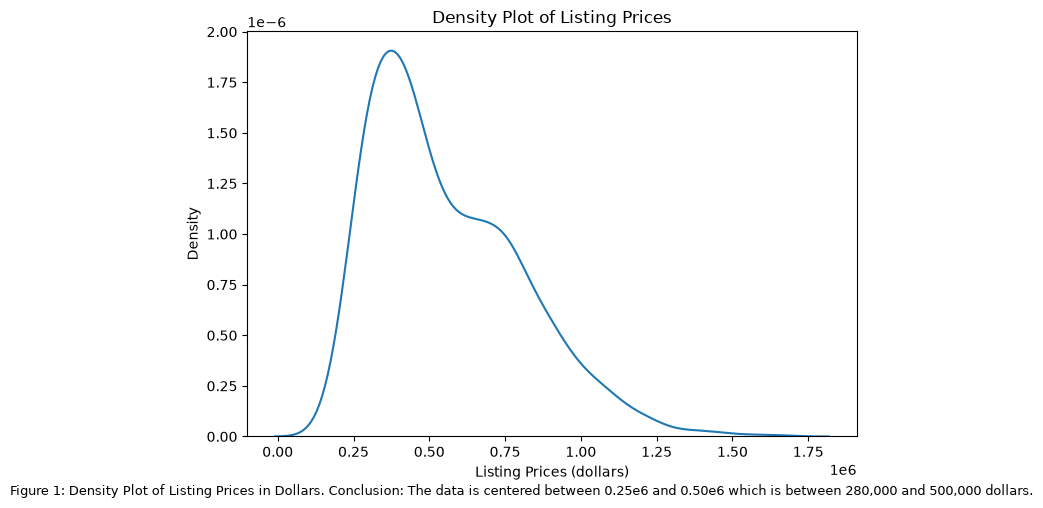

In [27]:
#Distribution plot 
fig_1, ax = plt.subplots(
    figsize=(7, 5)
)

sns.kdeplot(
    data=processed_data,
    x="ListPrice"
)

ax.set(
    title=(
        "Density Plot of Listing Prices"
    ),
    xlabel="Listing Prices (dollars)",
    ylabel="Density"
)

fig_1.text(
    0.5,           # x position
    0.00,          # y position
    "Figure 1: Density Plot of Listing Prices in Dollars. " \
    "Conclusion: The data is centered between 0.25e6 and 0.50e6 which is " \
    "between 280,000 and 500,000 dollars.",
    ha="center",
    fontsize=9
)
fig_1.tight_layout()


figure_1_path = ("../figures/"
                 "figure_1_density_plot_1.png")
fig_1.savefig(
    figure_1_path,
    dpi=300,
    bbox_inches="tight"
)

Conclusion: 

Based on this density plot, this data seems to right-skewed with the center of the data in between $200,000 and $500,00. This is showing that most of the data is between the two of these values. This does make sense since our median listing price was approximately $498,690 and the the mean listing price was approximately $558,711.10.

Comparison Plot Purpose: 

For the comparison plot, a comparison will be done on how Listing Price is distributed among the different conditions of the homes. I will do this using a boxplot.

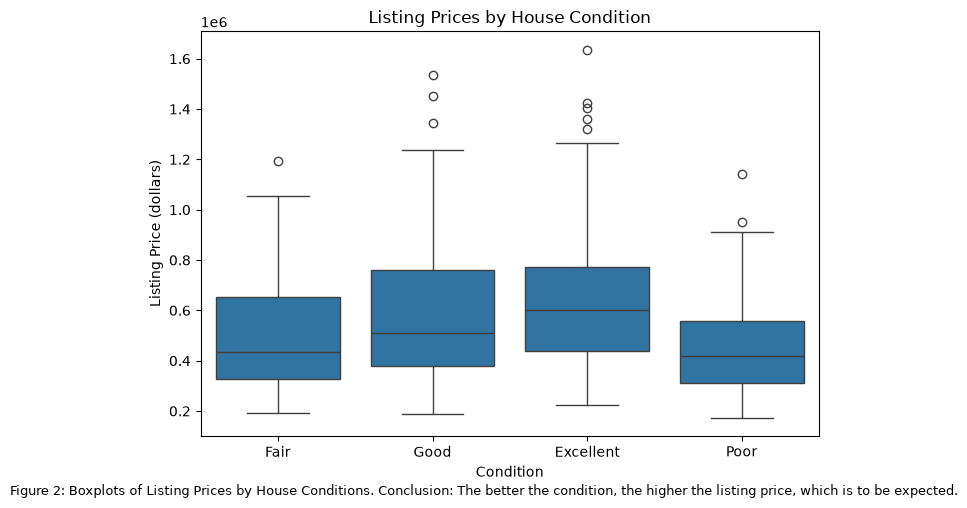

In [28]:
#Comparison plot

fig_2, ax = plt.subplots(
    figsize=(7, 5)
)

sns.boxplot(
    data=processed_data,
    x="Condition",
    y="ListPrice"
)
ax.set(
    title=(
        "Listing Prices by House Condition"),
        ylabel= ("Listing Price (dollars)")
    )

fig_2.text(
    0.5,           # x position
    0.00,          # y position
    "Figure 2: Boxplots of Listing Prices by House Conditions. " \
    "Conclusion: The better the condition, the higher the listing price, which is to be expected."\
        ,
    ha="center",
    fontsize=9)

fig_2.tight_layout()


figure_2_path = ("../figures/"
                 "figure_2_boxplot.png")
fig_2.savefig(
    figure_2_path,
    dpi=300,
    bbox_inches="tight")

Conclusion: 

Based on the Listing Price among condition, it seems as if the better the condition from Poor to Excellent, the higher the listing price, which is expected. As far as variability goes, the conditions that have the most variability are the homes in Good and Excellent conditions. This variability may not be completely explained by condition though, there could be other factors that could play into the variability of listing prices for these conditions of homes. One factor may be location and another may be square footage. Further analysis will need to be done to help explain the variability between the prices for these conditions of homes. Another important observation is that every condition has at least one outlier and these outliers are for the most expensive homes with that condition. This may reveal that sometimes, the condition of the home does not dictate the listing price of the home (there may be other factors that go into the listing price of a home).

Relationship Plot Purpose: 

For the relationship plot, I want to see what the relationship is between square footage of a home and the listing price of the home. I think I will also color the points based on condition to see if there are any trends associated with each condition of the homes. 

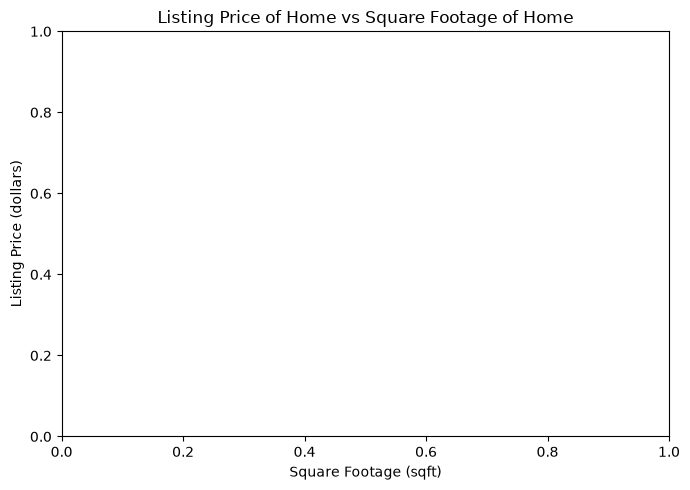

In [32]:
#Relationship plot
fig_3, ax = plt.subplots(
    figsize=(7, 5)
)
(
  ggplot(
        processed_data,
        aes(
            x="SqFt",
            y="ListPrice",
            colour ="Condition"
        )
    )
    + geom_point()
    + facet_wrap("Condition")
    )

ax.set(
    title="Listing Price of Home vs Square Footage of Home",
    xlabel="Square Footage (sqft)",
    ylabel="Listing Price (dollars)"
)

fig_3.tight_layout()

Conclusion: 